
=== Summary ===
Windows evaluated: 1471 (WIN_SEC=30, STEP_SEC=1)
Alerts (score_z >= 3.5): 538
First few alert window centers (sec): [356, 357, 358, 359, 360, 361, 362, 363, 364, 365]
Saved: cars_awareness_features.csv


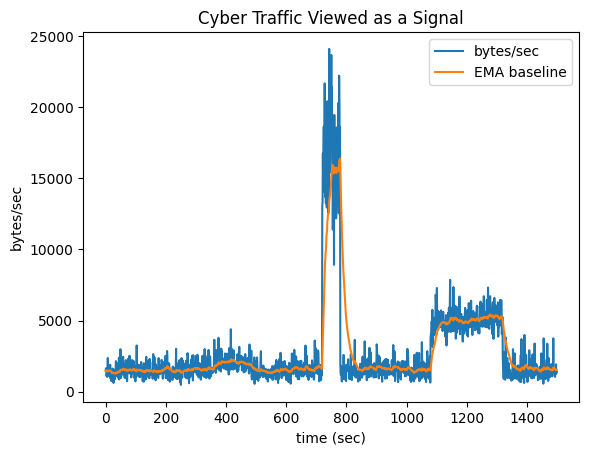

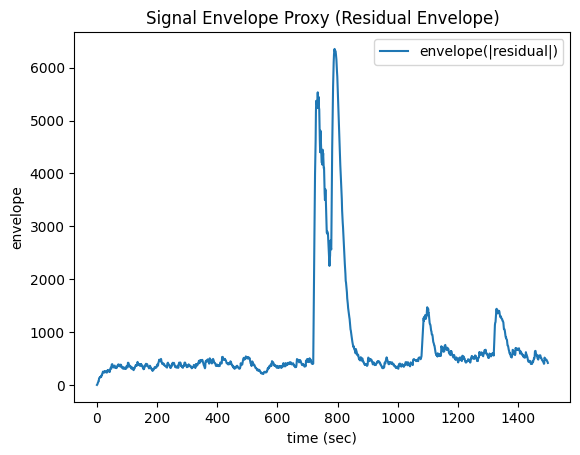

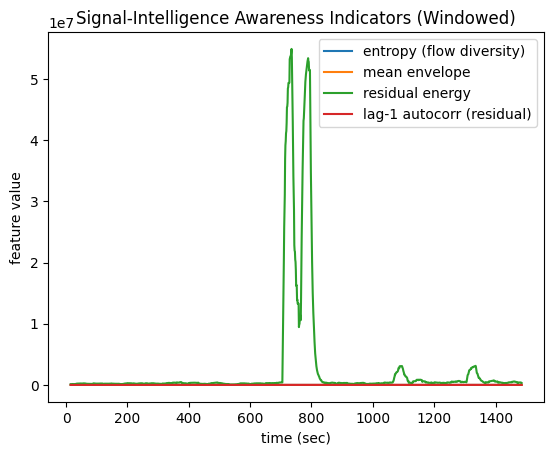

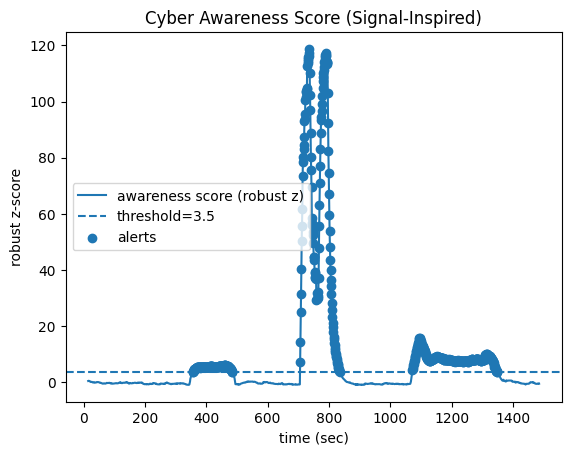

In [ ]:
"""
Cross-Domain Cyber Awareness Using Signal Intelligence (Runnable Demo)

What this script does:
1) Creates (or loads) a time-series of "traffic as a signal" (bytes per second).
2) Computes signal-intelligence-inspired awareness features:
   - Envelope statistics (EMA-based upper/lower envelope + residual energy)
   - Entropy dynamics (Shannon entropy of flow distribution per window)
   - Temporal correlation (lag-1 autocorrelation of the residual)
3) Produces an "awareness score" and flags anomalies using robust thresholds.
4) Plots everything.

Requirements:
  pip install numpy pandas matplotlib
(Optional) If you want SciPy-style peak detection, not used here.

Run:
  python cars_signal_intel_cyber_awareness.py

If you have real data:
- Provide a CSV with columns: ts, bytes, (optional) flow_id
- Update CSV_PATH below and set USE_SYNTHETIC=False
"""

import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =========================
# Configuration
# =========================
USE_SYNTHETIC = True
CSV_PATH = "traffic.csv"   # used only if USE_SYNTHETIC=False

FS_HZ = 1                  # samples per second (1 row per second)
WIN_SEC = 30               # sliding window size
STEP_SEC = 1               # sliding step

# Robust anomaly threshold (higher -> fewer alerts)
Z_THRESH = 3.5

# Synthetic scenario parameters (used if USE_SYNTHETIC=True)
DURATION_SEC = 25 * 60     # 25 minutes
SEED = 7

# =========================
# Helpers
# =========================
def shannon_entropy(counts: np.ndarray) -> float:
    """Shannon entropy in bits for nonnegative counts."""
    counts = counts.astype(float)
    s = counts.sum()
    if s <= 0:
        return 0.0
    p = counts / s
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum())

def ema(x: np.ndarray, alpha: float) -> np.ndarray:
    """Exponential moving average."""
    y = np.empty_like(x, dtype=float)
    y[0] = x[0]
    for i in range(1, len(x)):
        y[i] = alpha * x[i] + (1.0 - alpha) * y[i - 1]
    return y

def median_abs_deviation(x: np.ndarray) -> float:
    """MAD (median absolute deviation)."""
    m = np.median(x)
    return float(np.median(np.abs(x - m)))

def robust_z(x: np.ndarray) -> np.ndarray:
    """Robust z-score using MAD (scaled)."""
    m = np.median(x)
    mad = median_abs_deviation(x)
    # 1.4826 makes MAD comparable to std for Gaussian
    denom = 1.4826 * mad if mad > 1e-12 else 1e-12
    return (x - m) / denom

def lag1_autocorr(x: np.ndarray) -> float:
    """Lag-1 autocorrelation (safe for short/constant vectors)."""
    if len(x) < 3:
        return 0.0
    x0 = x[:-1]
    x1 = x[1:]
    v0 = x0 - x0.mean()
    v1 = x1 - x1.mean()
    d0 = np.sqrt((v0 * v0).sum())
    d1 = np.sqrt((v1 * v1).sum())
    if d0 < 1e-12 or d1 < 1e-12:
        return 0.0
    return float((v0 * v1).sum() / (d0 * d1))

# =========================
# Data generation / loading
# =========================
def generate_synthetic(duration_sec: int, seed: int = 7) -> pd.DataFrame:
    """
    Creates a synthetic traffic signal and a flow_id distribution per second.
    Scenarios:
      - Normal background
      - Port scan-like event: many small flows (entropy spike) + moderate bytes
      - DDoS-like burst: large bytes spike + strong correlation
      - Exfil-like event: sustained elevated bytes with lower entropy (few flows)
    """
    rng = np.random.default_rng(seed)
    t = np.arange(duration_sec)

    # Baseline bytes/sec: lognormal-ish
    base = rng.lognormal(mean=7.3, sigma=0.35, size=duration_sec)  # ~1500-2500 avg
    base = base.clip(200, None)

    bytes_sig = base.copy()

    # Event intervals
    scan_start, scan_end = 6*60, 8*60          # 6-8 min
    ddos_start, ddos_end = 12*60, 13*60        # 12-13 min
    exf_start, exf_end = 18*60, 22*60          # 18-22 min

    # Port scan: slightly elevated bytes, many small flows -> higher entropy
    bytes_sig[scan_start:scan_end] += rng.normal(600, 120, size=scan_end - scan_start).clip(0, None)

    # DDoS: big burst
    bytes_sig[ddos_start:ddos_end] += rng.normal(15000, 3500, size=ddos_end - ddos_start).clip(0, None)

    # Exfil: sustained elevated
    bytes_sig[exf_start:exf_end] += rng.normal(3500, 500, size=exf_end - exf_start).clip(0, None)

    bytes_sig = bytes_sig.clip(0, None)

    # Build per-second flow distributions (flow_id counts) to compute entropy
    flow_ids = []
    for i in range(duration_sec):
        if scan_start <= i < scan_end:
            # many flows, small counts
            n_flows = rng.integers(80, 140)
            counts = rng.poisson(lam=1.2, size=n_flows) + 1
        elif ddos_start <= i < ddos_end:
            # moderate number of flows, heavier tail
            n_flows = rng.integers(30, 60)
            counts = rng.poisson(lam=8.0, size=n_flows) + 1
        elif exf_start <= i < exf_end:
            # few flows dominate -> lower entropy
            n_flows = rng.integers(5, 12)
            counts = rng.poisson(lam=20.0, size=n_flows) + 1
            # add a dominant flow
            counts[0] += rng.integers(80, 160)
        else:
            # normal: moderate
            n_flows = rng.integers(15, 40)
            counts = rng.poisson(lam=4.0, size=n_flows) + 1

        # create flow_id list for this second
        # (flow_id repeats according to count)
        ids = []
        for k, c in enumerate(counts):
            ids += [f"f{k}"] * int(c)
        flow_ids.append(ids)

    df = pd.DataFrame({
        "ts": t,
        "bytes": bytes_sig.astype(float),
        "flow_ids": flow_ids
    })
    return df

def load_csv(path: str) -> pd.DataFrame:
    """
    Expected CSV formats:
      A) ts,bytes
         -> entropy is not computed (set to 0)
      B) ts,bytes,flow_id
         -> multiple rows per second allowed; we'll aggregate per second and compute entropy in windows
    """
    raw = pd.read_csv(path)

    if "ts" not in raw.columns or "bytes" not in raw.columns:
        raise ValueError("CSV must contain at least columns: ts, bytes")

    if "flow_id" not in raw.columns:
        # one row per second
        df = raw[["ts", "bytes"]].copy()
        df["ts"] = df["ts"].astype(int)
        df = df.sort_values("ts").reset_index(drop=True)
        df["flow_ids"] = [[] for _ in range(len(df))]
        return df

    # If flow_id exists: potentially multiple rows per second per flow
    raw["ts"] = raw["ts"].astype(int)
    raw["bytes"] = raw["bytes"].astype(float)

    # aggregate bytes per second
    bytes_per_sec = raw.groupby("ts")["bytes"].sum()

    # gather flow_id occurrences per second
    flows_per_sec = raw.groupby("ts")["flow_id"].apply(list)

    df = pd.DataFrame({
        "ts": bytes_per_sec.index.values,
        "bytes": bytes_per_sec.values,
        "flow_ids": flows_per_sec.values
    }).sort_values("ts").reset_index(drop=True)

    return df

# =========================
# Feature extraction (signal intelligence)
# =========================
def compute_features(df: pd.DataFrame, fs_hz: int, win_sec: int, step_sec: int) -> pd.DataFrame:
    x = df["bytes"].to_numpy(dtype=float)
    t = df["ts"].to_numpy(dtype=int)

    win = int(win_sec * fs_hz)
    step = int(step_sec * fs_hz)
    if win < 5:
        raise ValueError("WIN_SEC too small; use >= 5 seconds.")

    # Envelope modeling: EMA as baseline + residual
    # Choose alpha so that EMA "memory" ~ win seconds (rough heuristic)
    alpha = 2.0 / (win + 1.0)
    baseline = ema(x, alpha=alpha)
    residual = x - baseline

    # Upper/lower envelope via EMA of abs residual (acts like signal envelope)
    abs_res = np.abs(residual)
    env = ema(abs_res, alpha=alpha)

    # Sliding window features
    rows = []
    for start in range(0, len(x) - win + 1, step):
        end = start + win
        ts_mid = int(t[start + win // 2])

        seg_x = x[start:end]
        seg_res = residual[start:end]
        seg_env = env[start:end]

        # Envelope statistics
        mean_env = float(seg_env.mean())
        std_env = float(seg_env.std(ddof=0))
        energy_res = float(np.mean(seg_res ** 2))

        # Entropy: compute from flow distribution within window (if available)
        # We pool flow_ids across seconds in the window
        flow_ids_window = []
        for ids in df["flow_ids"].iloc[start:end]:
            flow_ids_window.extend(ids)

        if len(flow_ids_window) == 0:
            H = 0.0
        else:
            # counts per flow_id
            vc = pd.Series(flow_ids_window).value_counts().to_numpy()
            H = shannon_entropy(vc)

        # Temporal correlation: lag-1 autocorr of residual
        ac1 = lag1_autocorr(seg_res)

        rows.append({
            "ts": ts_mid,
            "mean_env": mean_env,
            "std_env": std_env,
            "res_energy": energy_res,
            "entropy": H,
            "ac1": ac1
        })

    feat = pd.DataFrame(rows)

    # Robust normalize and build an awareness score
    # (You can change weights; keep interpretable.)
    z_env = robust_z(feat["mean_env"].to_numpy())
    z_ent = robust_z(feat["entropy"].to_numpy())
    z_eng = robust_z(feat["res_energy"].to_numpy())
    z_ac1 = robust_z(feat["ac1"].to_numpy())

    # Awareness score: combine "how unusual" each indicator is
    # Typical interpretation:
    # - mean_env / res_energy: burstiness / magnitude anomalies
    # - entropy: scanning / flow diversity anomalies
    # - ac1: automated periodicity / sustained patterns
    score = (
        0.35 * np.abs(z_env) +
        0.25 * np.abs(z_ent) +
        0.25 * np.abs(z_eng) +
        0.15 * np.abs(z_ac1)
    )

    feat["score"] = score
    feat["score_z"] = robust_z(feat["score"].to_numpy())
    feat["alert"] = (feat["score_z"] >= Z_THRESH).astype(int)
    return feat, baseline, env

# =========================
# Main
# =========================
def main():
    if USE_SYNTHETIC:
        df = generate_synthetic(DURATION_SEC, seed=SEED)
    else:
        df = load_csv(CSV_PATH)

    feat, baseline, env = compute_features(df, FS_HZ, WIN_SEC, STEP_SEC)

    # Merge for plotting alignment
    t = df["ts"].to_numpy()
    x = df["bytes"].to_numpy()

    # Plot 1: Traffic as signal + baseline
    plt.figure()
    plt.plot(t, x, label="bytes/sec")
    plt.plot(t, baseline, label="EMA baseline")
    plt.title("Cyber Traffic Viewed as a Signal")
    plt.xlabel("time (sec)")
    plt.ylabel("bytes/sec")
    plt.legend()

    # Plot 2: Envelope magnitude (EMA of |residual|)
    plt.figure()
    plt.plot(t, env, label="envelope(|residual|)")
    plt.title("Signal Envelope Proxy (Residual Envelope)")
    plt.xlabel("time (sec)")
    plt.ylabel("envelope")
    plt.legend()

    # Plot 3: Awareness features over window centers
    plt.figure()
    plt.plot(feat["ts"], feat["entropy"], label="entropy (flow diversity)")
    plt.plot(feat["ts"], feat["mean_env"], label="mean envelope")
    plt.plot(feat["ts"], feat["res_energy"], label="residual energy")
    plt.plot(feat["ts"], feat["ac1"], label="lag-1 autocorr (residual)")
    plt.title("Signal-Intelligence Awareness Indicators (Windowed)")
    plt.xlabel("time (sec)")
    plt.ylabel("feature value")
    plt.legend()

    # Plot 4: Awareness score + alerts
    plt.figure()
    plt.plot(feat["ts"], feat["score_z"], label="awareness score (robust z)")
    plt.axhline(Z_THRESH, linestyle="--", label=f"threshold={Z_THRESH}")
    # mark alerts
    alert_ts = feat.loc[feat["alert"] == 1, "ts"].to_numpy()
    alert_vals = feat.loc[feat["alert"] == 1, "score_z"].to_numpy()
    if len(alert_ts) > 0:
        plt.scatter(alert_ts, alert_vals, label="alerts")
    plt.title("Cyber Awareness Score (Signal-Inspired)")
    plt.xlabel("time (sec)")
    plt.ylabel("robust z-score")
    plt.legend()

    print("\n=== Summary ===")
    print(f"Windows evaluated: {len(feat)} (WIN_SEC={WIN_SEC}, STEP_SEC={STEP_SEC})")
    print(f"Alerts (score_z >= {Z_THRESH}): {int(feat['alert'].sum())}")
    if int(feat["alert"].sum()) > 0:
        print("First few alert window centers (sec):", alert_ts[:10].tolist())

    # Save outputs for your paper
    feat.to_csv("cars_awareness_features.csv", index=False)
    print("Saved: cars_awareness_features.csv")

    plt.show()

if __name__ == "__main__":
    main()



=== Summary ===
Windows evaluated: 1471 (WIN_SEC=30, STEP_SEC=1)
Alerts (score_z >= 3.5): 538
First few alert window centers (sec): [356, 357, 358, 359, 360, 361, 362, 363, 364, 365]
Saved: cars_awareness_features.csv


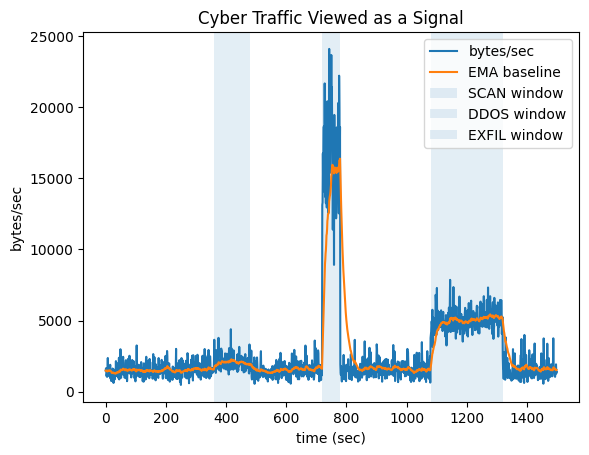

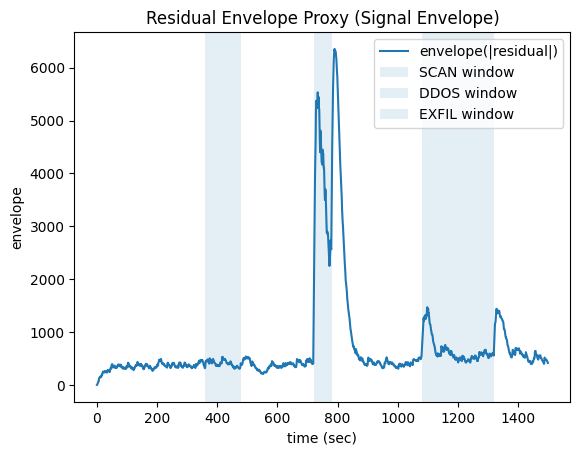

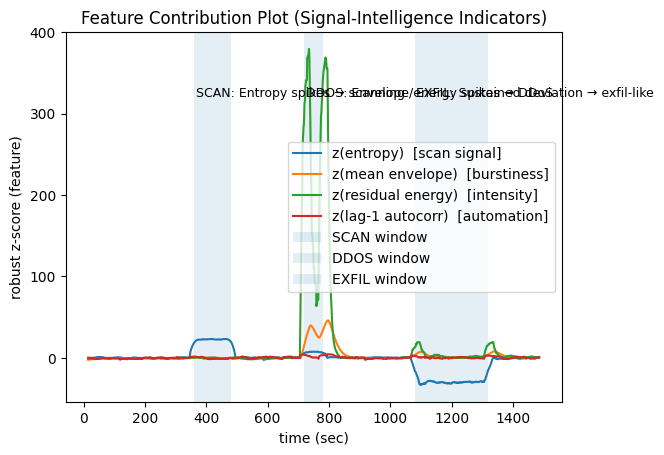

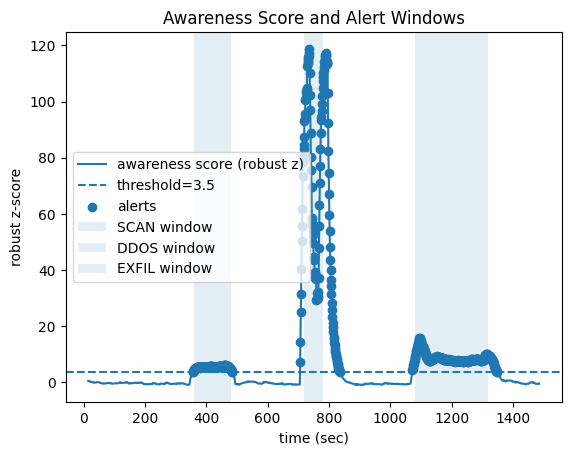

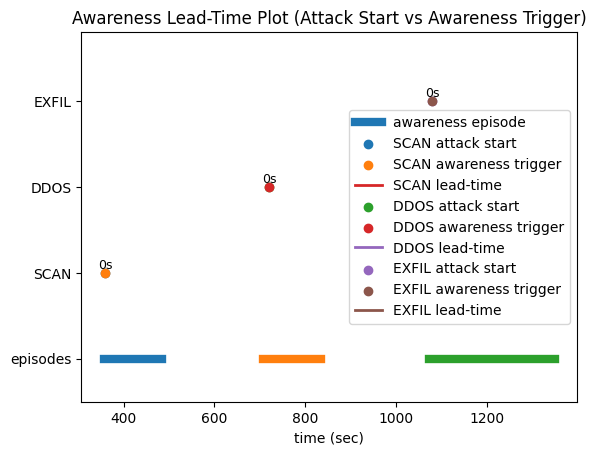

In [ ]:
"""
UPDATED: Cross-Domain Cyber Awareness Using Signal Intelligence
Adds BOTH:
(A) Awareness Lead-Time Plot: attack start time vs awareness trigger time (per episode)
(B) Feature Contribution Plot: entropy -> scanning, envelope energy -> DDoS, autocorr -> automation

Dependencies:
  pip install numpy pandas matplotlib pandas

Run:
  python cars_signal_intel_cyber_awareness_updated.py

Outputs:
  - cars_awareness_features.csv
  - Plots:
      1) Traffic + baseline
      2) Residual envelope
      3) Feature contribution plot (z-scored features + event shading)
      4) Awareness score + alerts
      5) Awareness lead-time plot (episodes vs attack start/trigger)
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =========================
# Configuration
# =========================
USE_SYNTHETIC = True
CSV_PATH = "traffic.csv"   # used only if USE_SYNTHETIC=False

FS_HZ = 1                  # samples per second (1 row per second)
WIN_SEC = 30               # sliding window size
STEP_SEC = 1               # sliding step

# Robust anomaly threshold (higher -> fewer alerts)
Z_THRESH = 3.5

# Episode merging (group consecutive alert windows into one episode)
EPISODE_GAP_SEC = 3        # allow tiny gaps between alert windows (seconds)

# Synthetic scenario parameters (used if USE_SYNTHETIC=True)
DURATION_SEC = 25 * 60     # 25 minutes
SEED = 7

# =========================
# Helpers
# =========================
def shannon_entropy(counts: np.ndarray) -> float:
    counts = counts.astype(float)
    s = counts.sum()
    if s <= 0:
        return 0.0
    p = counts / s
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum())

def ema(x: np.ndarray, alpha: float) -> np.ndarray:
    y = np.empty_like(x, dtype=float)
    y[0] = x[0]
    for i in range(1, len(x)):
        y[i] = alpha * x[i] + (1.0 - alpha) * y[i - 1]
    return y

def median_abs_deviation(x: np.ndarray) -> float:
    m = np.median(x)
    return float(np.median(np.abs(x - m)))

def robust_z(x: np.ndarray) -> np.ndarray:
    m = np.median(x)
    mad = median_abs_deviation(x)
    denom = 1.4826 * mad if mad > 1e-12 else 1e-12
    return (x - m) / denom

def lag1_autocorr(x: np.ndarray) -> float:
    if len(x) < 3:
        return 0.0
    x0 = x[:-1]
    x1 = x[1:]
    v0 = x0 - x0.mean()
    v1 = x1 - x1.mean()
    d0 = np.sqrt((v0 * v0).sum())
    d1 = np.sqrt((v1 * v1).sum())
    if d0 < 1e-12 or d1 < 1e-12:
        return 0.0
    return float((v0 * v1).sum() / (d0 * d1))

# =========================
# Data generation / loading
# =========================
def generate_synthetic(duration_sec: int, seed: int = 7):
    """
    Synthetic events (sec):
      - SCAN: 6:00 to 8:00 (many small flows -> entropy spike + moderate bytes)
      - DDOS: 12:00 to 13:00 (large burst -> envelope/energy spike)
      - EXFIL: 18:00 to 22:00 (sustained elevated bytes with fewer dominant flows)
    """
    rng = np.random.default_rng(seed)
    t = np.arange(duration_sec)

    # Baseline bytes/sec (lognormal-ish)
    base = rng.lognormal(mean=7.3, sigma=0.35, size=duration_sec)
    base = base.clip(200, None)
    bytes_sig = base.copy()

    # Event intervals
    scan = (6*60, 8*60)
    ddos = (12*60, 13*60)
    exfil = (18*60, 22*60)

    # Port scan: slightly elevated bytes, many small flows -> higher entropy
    bytes_sig[scan[0]:scan[1]] += rng.normal(600, 120, size=scan[1]-scan[0]).clip(0, None)

    # DDoS: big burst
    bytes_sig[ddos[0]:ddos[1]] += rng.normal(15000, 3500, size=ddos[1]-ddos[0]).clip(0, None)

    # Exfil: sustained elevated
    bytes_sig[exfil[0]:exfil[1]] += rng.normal(3500, 500, size=exfil[1]-exfil[0]).clip(0, None)

    bytes_sig = bytes_sig.clip(0, None)

    # Per-second flow distributions (for entropy)
    flow_ids = []
    for i in range(duration_sec):
        if scan[0] <= i < scan[1]:
            n_flows = rng.integers(80, 140)
            counts = rng.poisson(lam=1.2, size=n_flows) + 1
        elif ddos[0] <= i < ddos[1]:
            n_flows = rng.integers(30, 60)
            counts = rng.poisson(lam=8.0, size=n_flows) + 1
        elif exfil[0] <= i < exfil[1]:
            n_flows = rng.integers(5, 12)
            counts = rng.poisson(lam=20.0, size=n_flows) + 1
            counts[0] += rng.integers(80, 160)  # dominant flow -> lower entropy
        else:
            n_flows = rng.integers(15, 40)
            counts = rng.poisson(lam=4.0, size=n_flows) + 1

        ids = []
        for k, c in enumerate(counts):
            ids += [f"f{k}"] * int(c)
        flow_ids.append(ids)

    df = pd.DataFrame({"ts": t, "bytes": bytes_sig.astype(float), "flow_ids": flow_ids})

    # Event metadata for plotting + lead-time analysis
    events = [
        {"name": "SCAN", "start": scan[0], "end": scan[1], "feature_story": "Entropy spikes → scanning"},
        {"name": "DDOS", "start": ddos[0], "end": ddos[1], "feature_story": "Envelope/energy spikes → DDoS"},
        {"name": "EXFIL", "start": exfil[0], "end": exfil[1], "feature_story": "Sustained deviation → exfil-like"},
    ]
    return df, events

def load_csv(path: str):
    """
    Expected CSV formats:
      A) ts,bytes
      B) ts,bytes,flow_id  (multiple rows per second allowed)
    """
    raw = pd.read_csv(path)
    if "ts" not in raw.columns or "bytes" not in raw.columns:
        raise ValueError("CSV must contain at least columns: ts, bytes")

    if "flow_id" not in raw.columns:
        df = raw[["ts", "bytes"]].copy()
        df["ts"] = df["ts"].astype(int)
        df = df.sort_values("ts").reset_index(drop=True)
        df["flow_ids"] = [[] for _ in range(len(df))]
        return df, []

    raw["ts"] = raw["ts"].astype(int)
    raw["bytes"] = raw["bytes"].astype(float)

    bytes_per_sec = raw.groupby("ts")["bytes"].sum()
    flows_per_sec = raw.groupby("ts")["flow_id"].apply(list)

    df = pd.DataFrame({
        "ts": bytes_per_sec.index.values,
        "bytes": bytes_per_sec.values,
        "flow_ids": flows_per_sec.values
    }).sort_values("ts").reset_index(drop=True)

    return df, []

# =========================
# Feature extraction
# =========================
def compute_features(df: pd.DataFrame, fs_hz: int, win_sec: int, step_sec: int):
    x = df["bytes"].to_numpy(dtype=float)
    t = df["ts"].to_numpy(dtype=int)

    win = int(win_sec * fs_hz)
    step = int(step_sec * fs_hz)
    if win < 5:
        raise ValueError("WIN_SEC too small; use >= 5 seconds.")

    # Envelope modeling: EMA baseline + residual
    alpha = 2.0 / (win + 1.0)
    baseline = ema(x, alpha=alpha)
    residual = x - baseline

    # Envelope proxy: EMA of |residual|
    abs_res = np.abs(residual)
    env = ema(abs_res, alpha=alpha)

    rows = []
    for start in range(0, len(x) - win + 1, step):
        end = start + win
        ts_mid = int(t[start + win // 2])

        seg_res = residual[start:end]
        seg_env = env[start:end]

        mean_env = float(seg_env.mean())
        std_env = float(seg_env.std(ddof=0))
        res_energy = float(np.mean(seg_res ** 2))
        ac1 = lag1_autocorr(seg_res)

        flow_ids_window = []
        for ids in df["flow_ids"].iloc[start:end]:
            flow_ids_window.extend(ids)

        if len(flow_ids_window) == 0:
            H = 0.0
        else:
            vc = pd.Series(flow_ids_window).value_counts().to_numpy()
            H = shannon_entropy(vc)

        rows.append({
            "ts": ts_mid,
            "mean_env": mean_env,
            "std_env": std_env,
            "res_energy": res_energy,
            "entropy": H,
            "ac1": ac1
        })

    feat = pd.DataFrame(rows)

    # Robust z for contributions
    feat["z_mean_env"] = robust_z(feat["mean_env"].to_numpy())
    feat["z_entropy"] = robust_z(feat["entropy"].to_numpy())
    feat["z_res_energy"] = robust_z(feat["res_energy"].to_numpy())
    feat["z_ac1"] = robust_z(feat["ac1"].to_numpy())

    # Awareness score (interpretable weighted combination)
    score = (
        0.35 * np.abs(feat["z_mean_env"].to_numpy()) +
        0.25 * np.abs(feat["z_entropy"].to_numpy()) +
        0.25 * np.abs(feat["z_res_energy"].to_numpy()) +
        0.15 * np.abs(feat["z_ac1"].to_numpy())
    )
    feat["score"] = score
    feat["score_z"] = robust_z(feat["score"].to_numpy())
    feat["alert"] = (feat["score_z"] >= Z_THRESH).astype(int)
    return feat, baseline, env

# =========================
# Episode logic + lead-time
# =========================
def merge_alerts_to_episodes(feat: pd.DataFrame, gap_sec: int):
    """
    Merge consecutive alert windows into episodes.
    Episode is a tuple: (start_ts, end_ts)
    """
    alert_ts = feat.loc[feat["alert"] == 1, "ts"].to_numpy(dtype=int)
    if len(alert_ts) == 0:
        return []

    alert_ts = np.sort(alert_ts)
    episodes = []
    s = alert_ts[0]
    e = alert_ts[0]
    for ts in alert_ts[1:]:
        if ts <= e + gap_sec:
            e = ts
        else:
            episodes.append((int(s), int(e)))
            s, e = ts, ts
    episodes.append((int(s), int(e)))
    return episodes

def first_trigger_after(feat: pd.DataFrame, start_time: int):
    """
    Find the first alert ts >= start_time (awareness trigger time).
    Returns None if no trigger.
    """
    hits = feat.loc[(feat["alert"] == 1) & (feat["ts"] >= start_time), "ts"]
    if len(hits) == 0:
        return None
    return int(hits.iloc[0])

# =========================
# Plot helpers
# =========================
def shade_events(ax, events):
    for ev in events:
        ax.axvspan(ev["start"], ev["end"], alpha=0.12, label=f'{ev["name"]} window')

def add_unique_legend(ax):
    handles, labels = ax.get_legend_handles_labels()
    seen = set()
    h2, l2 = [], []
    for h, l in zip(handles, labels):
        if l not in seen:
            h2.append(h); l2.append(l); seen.add(l)
    if len(l2) > 0:
        ax.legend(h2, l2)

# =========================
# Main
# =========================
def main():
    if USE_SYNTHETIC:
        df, events = generate_synthetic(DURATION_SEC, seed=SEED)
    else:
        df, events = load_csv(CSV_PATH)

    feat, baseline, env = compute_features(df, FS_HZ, WIN_SEC, STEP_SEC)

    # Save for paper
    feat.to_csv("cars_awareness_features.csv", index=False)
    print("\n=== Summary ===")
    print(f"Windows evaluated: {len(feat)} (WIN_SEC={WIN_SEC}, STEP_SEC={STEP_SEC})")
    print(f"Alerts (score_z >= {Z_THRESH}): {int(feat['alert'].sum())}")
    if int(feat["alert"].sum()) > 0:
        alert_ts = feat.loc[feat["alert"] == 1, "ts"].to_numpy()
        print("First few alert window centers (sec):", alert_ts[:10].tolist())
    print("Saved: cars_awareness_features.csv")

    # =========================
    # Plot 1: Traffic as signal + baseline
    # =========================
    t = df["ts"].to_numpy()
    x = df["bytes"].to_numpy()

    fig1, ax1 = plt.subplots()
    ax1.plot(t, x, label="bytes/sec")
    ax1.plot(t, baseline, label="EMA baseline")
    if events:
        shade_events(ax1, events)
    ax1.set_title("Cyber Traffic Viewed as a Signal")
    ax1.set_xlabel("time (sec)")
    ax1.set_ylabel("bytes/sec")
    add_unique_legend(ax1)

    # =========================
    # Plot 2: Residual envelope
    # =========================
    fig2, ax2 = plt.subplots()
    ax2.plot(t, env, label="envelope(|residual|)")
    if events:
        shade_events(ax2, events)
    ax2.set_title("Residual Envelope Proxy (Signal Envelope)")
    ax2.set_xlabel("time (sec)")
    ax2.set_ylabel("envelope")
    add_unique_legend(ax2)

    # =========================
    # Plot 3 (Option B): Feature contribution plot
    # Focus mapping:
    #  - Entropy spikes → scanning
    #  - Envelope energy (mean_env or res_energy) → DDoS
    #  - Autocorrelation → automation
    # =========================
    fig3, ax3 = plt.subplots()
    # Use z-scored features so they are on comparable scale
    ax3.plot(feat["ts"], feat["z_entropy"], label="z(entropy)  [scan signal]")
    ax3.plot(feat["ts"], feat["z_mean_env"], label="z(mean envelope)  [burstiness]")
    ax3.plot(feat["ts"], feat["z_res_energy"], label="z(residual energy)  [intensity]")
    ax3.plot(feat["ts"], feat["z_ac1"], label="z(lag-1 autocorr)  [automation]")
    if events:
        shade_events(ax3, events)
    ax3.set_title("Feature Contribution Plot (Signal-Intelligence Indicators)")
    ax3.set_xlabel("time (sec)")
    ax3.set_ylabel("robust z-score (feature)")
    add_unique_legend(ax3)

    # Add short text annotations if synthetic
    if events:
        # place annotation near event start for clarity
        for ev in events:
            ax3.text(ev["start"] + 5, ax3.get_ylim()[1] * 0.8, f'{ev["name"]}: {ev["feature_story"]}', fontsize=9)

    # =========================
    # Plot 4: Awareness score + alerts
    # =========================
    fig4, ax4 = plt.subplots()
    ax4.plot(feat["ts"], feat["score_z"], label="awareness score (robust z)")
    ax4.axhline(Z_THRESH, linestyle="--", label=f"threshold={Z_THRESH}")
    alert_mask = (feat["alert"] == 1)
    if alert_mask.any():
        ax4.scatter(feat.loc[alert_mask, "ts"], feat.loc[alert_mask, "score_z"], label="alerts")
    if events:
        shade_events(ax4, events)
    ax4.set_title("Awareness Score and Alert Windows")
    ax4.set_xlabel("time (sec)")
    ax4.set_ylabel("robust z-score")
    add_unique_legend(ax4)

    # =========================
    # Plot 5 (Option A): Awareness lead-time plot
    # Shows attack start time vs awareness trigger time (per event) AND episodes
    # =========================
    fig5, ax5 = plt.subplots()

    # Episode view (from alert windows)
    episodes = merge_alerts_to_episodes(feat, gap_sec=EPISODE_GAP_SEC)
    if len(episodes) > 0:
        # draw episodes as horizontal segments at y=0
        for (s, e) in episodes:
            ax5.plot([s, e], [0, 0], linewidth=6, label="awareness episode")

    # Event start vs trigger markers (synthetic only)
    if events:
        y = 1.0
        for ev in events:
            start = ev["start"]
            trigger = first_trigger_after(feat, start_time=start)

            # Attack start marker
            ax5.scatter([start], [y], label=f'{ev["name"]} attack start')

            if trigger is not None:
                ax5.scatter([trigger], [y], label=f'{ev["name"]} awareness trigger')
                # draw lead-time arrow line
                ax5.plot([start, trigger], [y, y], linewidth=2, label=f'{ev["name"]} lead-time')
                # annotate lead time
                lead = trigger - start
                ax5.text((start + trigger) / 2.0, y + 0.05, f"{lead}s", ha="center", fontsize=9)
            else:
                ax5.text(start, y + 0.05, "no trigger", fontsize=9)

            y += 1.0

    ax5.set_title("Awareness Lead-Time Plot (Attack Start vs Awareness Trigger)")
    ax5.set_xlabel("time (sec)")
    ax5.set_yticks([0, 1, 2, 3])
    ax5.set_yticklabels(["episodes", "SCAN", "DDOS", "EXFIL"] if events else ["episodes", "", "", ""])
    ax5.set_ylim(-0.5, 3.8)
    add_unique_legend(ax5)

    plt.show()

if __name__ == "__main__":
    main()



=== Summary ===
Windows evaluated: 1471 (WIN_SEC=30, STEP_SEC=1)
Alerts (score_z >= 3.5): 538
First few alert window centers (sec): [356, 357, 358, 359, 360, 361, 362, 363, 364, 365]
Saved: cars_awareness_features.csv
Saved: cars_awareness_episodes.csv
Saved: cars_awareness_summary.csv
Saved: cars_awareness_event_lead_time.csv
Saved: cars_awareness_results_table.csv

TABLE 1 — Overall Summary (Experiment + Awareness Monitoring)
 total_duration_sec  fs_hz  win_sec  step_sec  windows_evaluated  z_thresh  alerts_windows  alert_rate  episodes_count  episodes_total_duration_sec  episodes_total_duration_percent
               1500      1       30         1               1471       3.5             538    0.365738               3                          538                        35.866667

TABLE 2 — Awareness Episodes (Merged Consecutive Alert Windows)
 episode_id  start_ts  end_ts  duration_sec
          1       356     485           130
          2       706     835           130
        

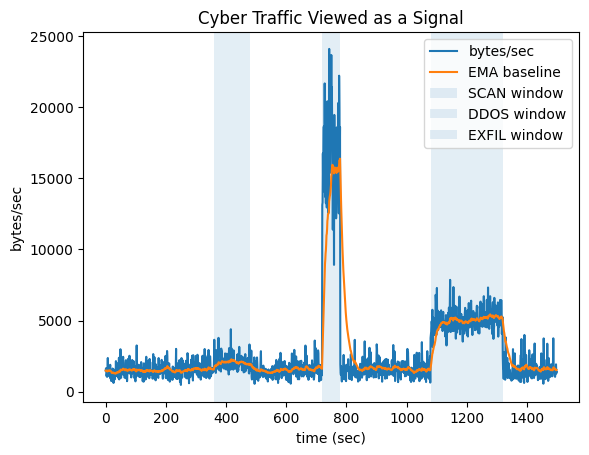

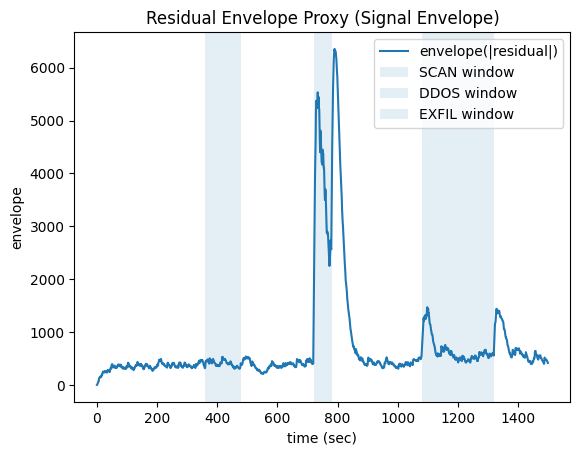

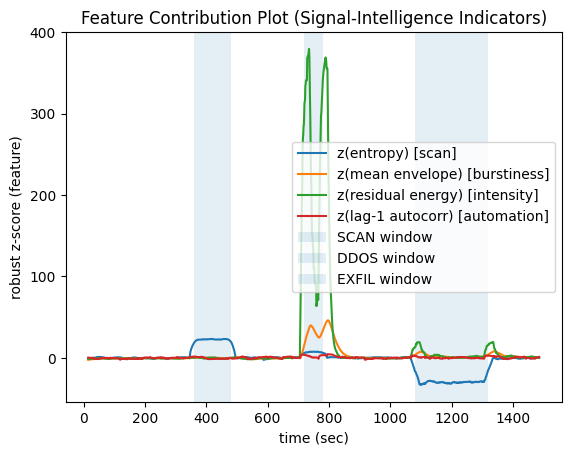

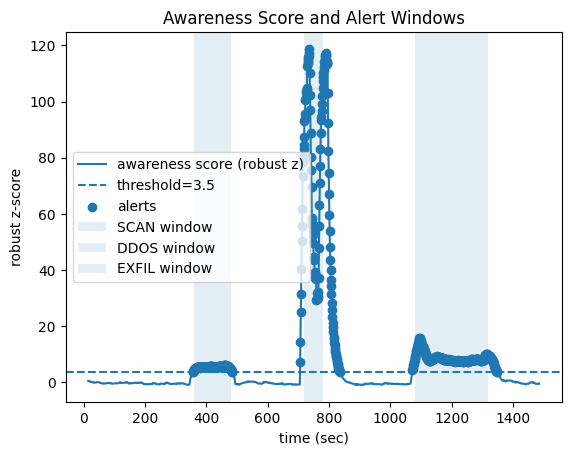

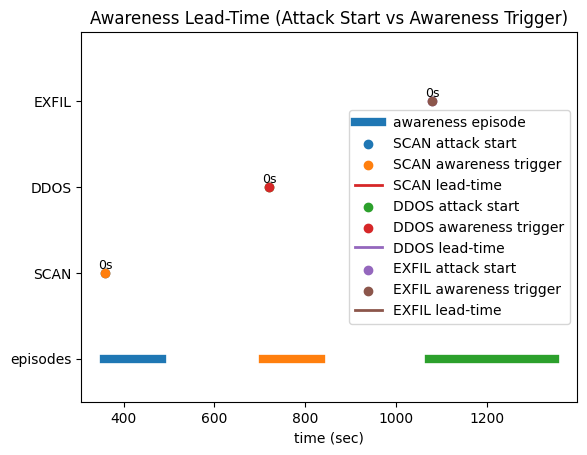

In [ ]:
--


=== Summary ===
Windows evaluated: 1471 (WIN_SEC=30, STEP_SEC=1)
Alerts (score_z >= 3.5): 538
First few alert window centers (sec): [356, 357, 358, 359, 360, 361, 362, 363, 364, 365]
Saved: cars_awareness_features.csv
Saved: cars_awareness_episodes.csv
Saved: cars_awareness_summary.csv
Saved: cars_awareness_event_lead_time.csv
Saved: cars_awareness_results_table.csv

TABLE 1 — Overall Summary (Experiment + Awareness Monitoring)
 total_duration_sec  fs_hz  win_sec  step_sec  windows_evaluated  z_thresh  alerts_windows  alert_rate  episodes_count  episodes_total_duration_sec  episodes_total_duration_percent
               1500      1       30         1               1471       3.5             538    0.365738               3                          538                        35.866667

TABLE 2 — Awareness Episodes (Merged Consecutive Alert Windows)
 episode_id  start_ts  end_ts  duration_sec
          1       356     485           130
          2       706     835           130
        

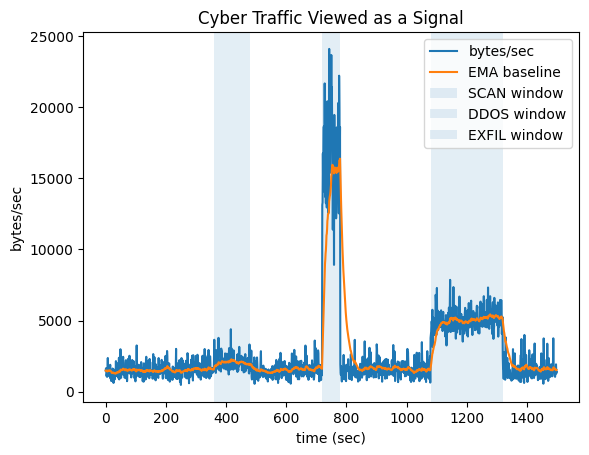

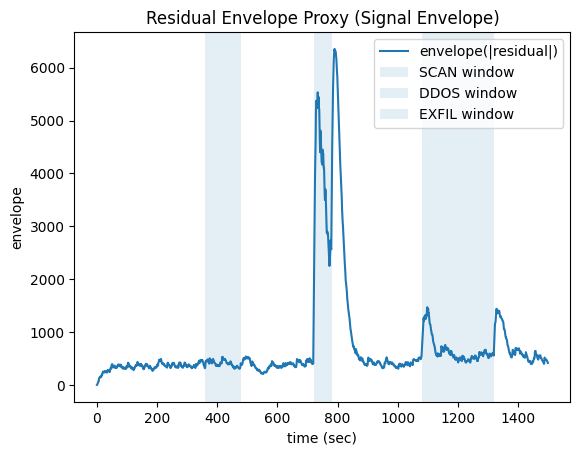

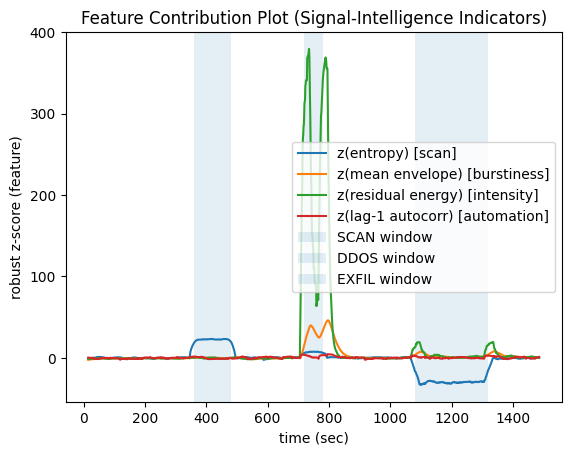

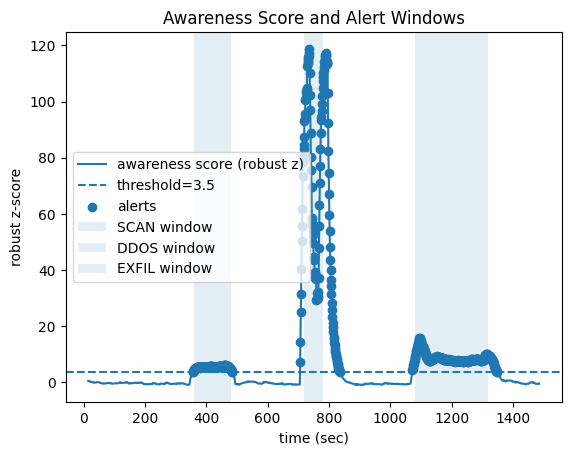

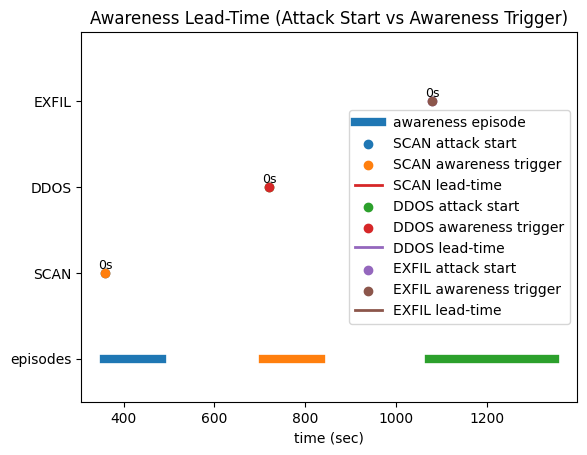

In [2]:
"""
FULL PIPELINE (CARS): tables + all plots + saved results

What you get:
1) All plots (5 figures):
   - Traffic + baseline (with event shading)
   - Residual envelope
   - Feature contribution plot (z-scored features)
   - Awareness score + alerts
   - Awareness lead-time plot (attack start vs trigger + awareness episodes)
2) Printed tables in console AND saved CSV tables:
   - cars_awareness_features.csv          (window-level features)
   - cars_awareness_episodes.csv          (merged alert episodes)
   - cars_awareness_event_lead_time.csv   (attack start vs trigger + lead time)
   - cars_awareness_summary.csv           (overall summary metrics)
3) Clean “Results” table you can paste into paper:
   - per-event lead time, episode overlap, alert density, key feature spikes

Dependencies:
  pip install numpy pandas matplotlib

Run:
  python cars_full_results.py

Notes:
- Works with synthetic data out-of-box (USE_SYNTHETIC=True)
- For real data: set USE_SYNTHETIC=False and provide traffic.csv (ts,bytes[,flow_id])
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =========================
# Configuration
# =========================
USE_SYNTHETIC = True
CSV_PATH = "traffic.csv"   # used only if USE_SYNTHETIC=False

FS_HZ = 1
WIN_SEC = 30
STEP_SEC = 1

Z_THRESH = 3.5
EPISODE_GAP_SEC = 3  # merge consecutive alert windows into episodes allowing small gaps

# Synthetic
DURATION_SEC = 25 * 60
SEED = 7

# Output files
OUT_FEATURES = "cars_awareness_features.csv"
OUT_EPISODES = "cars_awareness_episodes.csv"
OUT_EVENT_LEAD = "cars_awareness_event_lead_time.csv"
OUT_SUMMARY = "cars_awareness_summary.csv"
OUT_RESULTS_TABLE = "cars_awareness_results_table.csv"

# =========================
# Helpers
# =========================
def shannon_entropy(counts: np.ndarray) -> float:
    counts = counts.astype(float)
    s = counts.sum()
    if s <= 0:
        return 0.0
    p = counts / s
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum())

def ema(x: np.ndarray, alpha: float) -> np.ndarray:
    y = np.empty_like(x, dtype=float)
    y[0] = x[0]
    for i in range(1, len(x)):
        y[i] = alpha * x[i] + (1.0 - alpha) * y[i - 1]
    return y

def median_abs_deviation(x: np.ndarray) -> float:
    m = np.median(x)
    return float(np.median(np.abs(x - m)))

def robust_z(x: np.ndarray) -> np.ndarray:
    m = np.median(x)
    mad = median_abs_deviation(x)
    denom = 1.4826 * mad if mad > 1e-12 else 1e-12
    return (x - m) / denom

def lag1_autocorr(x: np.ndarray) -> float:
    if len(x) < 3:
        return 0.0
    x0 = x[:-1]
    x1 = x[1:]
    v0 = x0 - x0.mean()
    v1 = x1 - x1.mean()
    d0 = np.sqrt((v0 * v0).sum())
    d1 = np.sqrt((v1 * v1).sum())
    if d0 < 1e-12 or d1 < 1e-12:
        return 0.0
    return float((v0 * v1).sum() / (d0 * d1))

def format_sec(s: int) -> str:
    m = s // 60
    r = s % 60
    return f"{m:02d}:{r:02d}"

def safe_float(x) -> float:
    try:
        return float(x)
    except Exception:
        return float("nan")

# =========================
# Data generation / loading
# =========================
def generate_synthetic(duration_sec: int, seed: int = 7):
    """
    Synthetic events (sec):
      - SCAN: 6:00 to 8:00
      - DDOS: 12:00 to 13:00
      - EXFIL: 18:00 to 22:00
    """
    rng = np.random.default_rng(seed)
    t = np.arange(duration_sec)

    base = rng.lognormal(mean=7.3, sigma=0.35, size=duration_sec).clip(200, None)
    bytes_sig = base.copy()

    scan = (6*60, 8*60)
    ddos = (12*60, 13*60)
    exfil = (18*60, 22*60)

    bytes_sig[scan[0]:scan[1]] += rng.normal(600, 120, size=scan[1]-scan[0]).clip(0, None)
    bytes_sig[ddos[0]:ddos[1]] += rng.normal(15000, 3500, size=ddos[1]-ddos[0]).clip(0, None)
    bytes_sig[exfil[0]:exfil[1]] += rng.normal(3500, 500, size=exfil[1]-exfil[0]).clip(0, None)
    bytes_sig = bytes_sig.clip(0, None)

    flow_ids = []
    for i in range(duration_sec):
        if scan[0] <= i < scan[1]:
            n_flows = rng.integers(80, 140)
            counts = rng.poisson(lam=1.2, size=n_flows) + 1
        elif ddos[0] <= i < ddos[1]:
            n_flows = rng.integers(30, 60)
            counts = rng.poisson(lam=8.0, size=n_flows) + 1
        elif exfil[0] <= i < exfil[1]:
            n_flows = rng.integers(5, 12)
            counts = rng.poisson(lam=20.0, size=n_flows) + 1
            counts[0] += rng.integers(80, 160)
        else:
            n_flows = rng.integers(15, 40)
            counts = rng.poisson(lam=4.0, size=n_flows) + 1

        ids = []
        for k, c in enumerate(counts):
            ids += [f"f{k}"] * int(c)
        flow_ids.append(ids)

    df = pd.DataFrame({"ts": t, "bytes": bytes_sig.astype(float), "flow_ids": flow_ids})

    events = [
        {"name": "SCAN", "start": scan[0], "end": scan[1], "type": "scan"},
        {"name": "DDOS", "start": ddos[0], "end": ddos[1], "type": "dos"},
        {"name": "EXFIL", "start": exfil[0], "end": exfil[1], "type": "exfil"},
    ]
    return df, events

def load_csv(path: str):
    """
    CSV formats:
      A) ts,bytes
      B) ts,bytes,flow_id  (multiple rows per second allowed)
    """
    raw = pd.read_csv(path)
    if "ts" not in raw.columns or "bytes" not in raw.columns:
        raise ValueError("CSV must contain at least columns: ts, bytes")

    if "flow_id" not in raw.columns:
        df = raw[["ts", "bytes"]].copy()
        df["ts"] = df["ts"].astype(int)
        df = df.sort_values("ts").reset_index(drop=True)
        df["flow_ids"] = [[] for _ in range(len(df))]
        return df, []

    raw["ts"] = raw["ts"].astype(int)
    raw["bytes"] = raw["bytes"].astype(float)

    bytes_per_sec = raw.groupby("ts")["bytes"].sum()
    flows_per_sec = raw.groupby("ts")["flow_id"].apply(list)

    df = pd.DataFrame({
        "ts": bytes_per_sec.index.values,
        "bytes": bytes_per_sec.values,
        "flow_ids": flows_per_sec.values
    }).sort_values("ts").reset_index(drop=True)

    return df, []

# =========================
# Feature extraction
# =========================
def compute_features(df: pd.DataFrame, fs_hz: int, win_sec: int, step_sec: int):
    x = df["bytes"].to_numpy(dtype=float)
    t = df["ts"].to_numpy(dtype=int)

    win = int(win_sec * fs_hz)
    step = int(step_sec * fs_hz)
    if win < 5:
        raise ValueError("WIN_SEC too small; use >= 5 seconds.")
    if step < 1:
        raise ValueError("STEP_SEC too small; use >= 1 second.")

    alpha = 2.0 / (win + 1.0)
    baseline = ema(x, alpha=alpha)
    residual = x - baseline

    abs_res = np.abs(residual)
    env = ema(abs_res, alpha=alpha)

    rows = []
    for start in range(0, len(x) - win + 1, step):
        end = start + win
        ts_mid = int(t[start + win // 2])

        seg_res = residual[start:end]
        seg_env = env[start:end]

        mean_env = float(seg_env.mean())
        std_env = float(seg_env.std(ddof=0))
        res_energy = float(np.mean(seg_res ** 2))
        ac1 = lag1_autocorr(seg_res)

        flow_ids_window = []
        for ids in df["flow_ids"].iloc[start:end]:
            flow_ids_window.extend(ids)

        if len(flow_ids_window) == 0:
            H = 0.0
        else:
            vc = pd.Series(flow_ids_window).value_counts().to_numpy()
            H = shannon_entropy(vc)

        rows.append({
            "ts": ts_mid,
            "mean_env": mean_env,
            "std_env": std_env,
            "res_energy": res_energy,
            "entropy": H,
            "ac1": ac1
        })

    feat = pd.DataFrame(rows)

    # Robust z for per-feature contribution
    feat["z_mean_env"] = robust_z(feat["mean_env"].to_numpy())
    feat["z_std_env"] = robust_z(feat["std_env"].to_numpy())
    feat["z_res_energy"] = robust_z(feat["res_energy"].to_numpy())
    feat["z_entropy"] = robust_z(feat["entropy"].to_numpy())
    feat["z_ac1"] = robust_z(feat["ac1"].to_numpy())

    # Awareness score
    score = (
        0.35 * np.abs(feat["z_mean_env"].to_numpy()) +
        0.25 * np.abs(feat["z_entropy"].to_numpy()) +
        0.25 * np.abs(feat["z_res_energy"].to_numpy()) +
        0.15 * np.abs(feat["z_ac1"].to_numpy())
    )
    feat["score"] = score
    feat["score_z"] = robust_z(feat["score"].to_numpy())
    feat["alert"] = (feat["score_z"] >= Z_THRESH).astype(int)

    return feat, baseline, env

# =========================
# Episodes + lead time
# =========================
def merge_alerts_to_episodes(feat: pd.DataFrame, gap_sec: int):
    alert_ts = feat.loc[feat["alert"] == 1, "ts"].to_numpy(dtype=int)
    if len(alert_ts) == 0:
        return pd.DataFrame(columns=["episode_id", "start_ts", "end_ts", "duration_sec"])

    alert_ts = np.sort(alert_ts)
    episodes = []
    s = int(alert_ts[0])
    e = int(alert_ts[0])
    ep_id = 1
    for ts in alert_ts[1:]:
        ts = int(ts)
        if ts <= e + gap_sec:
            e = ts
        else:
            episodes.append((ep_id, s, e, e - s + 1))
            ep_id += 1
            s, e = ts, ts
    episodes.append((ep_id, s, e, e - s + 1))

    return pd.DataFrame(episodes, columns=["episode_id", "start_ts", "end_ts", "duration_sec"])

def first_trigger_after(feat: pd.DataFrame, start_time: int):
    hits = feat.loc[(feat["alert"] == 1) & (feat["ts"] >= start_time), "ts"]
    if len(hits) == 0:
        return None
    return int(hits.iloc[0])

def overlap_duration(a_start, a_end, b_start, b_end) -> int:
    s = max(int(a_start), int(b_start))
    e = min(int(a_end), int(b_end))
    return max(0, e - s)

def event_episode_overlap(event, episodes_df) -> int:
    total = 0
    for _, ep in episodes_df.iterrows():
        total += overlap_duration(event["start"], event["end"], ep["start_ts"], ep["end_ts"])
    return int(total)

def dominant_feature_in_window(feat_slice: pd.DataFrame) -> str:
    """
    Pick which feature contributes most (by mean absolute z) in this interval.
    """
    if len(feat_slice) == 0:
        return "none"
    candidates = {
        "entropy": np.mean(np.abs(feat_slice["z_entropy"].to_numpy())),
        "mean_env": np.mean(np.abs(feat_slice["z_mean_env"].to_numpy())),
        "res_energy": np.mean(np.abs(feat_slice["z_res_energy"].to_numpy())),
        "ac1": np.mean(np.abs(feat_slice["z_ac1"].to_numpy())),
    }
    return max(candidates, key=candidates.get)

# =========================
# Plot utilities
# =========================
def shade_events(ax, events):
    for ev in events:
        ax.axvspan(ev["start"], ev["end"], alpha=0.12, label=f'{ev["name"]} window')

def unique_legend(ax):
    handles, labels = ax.get_legend_handles_labels()
    seen = set()
    h2, l2 = [], []
    for h, l in zip(handles, labels):
        if l not in seen:
            h2.append(h); l2.append(l); seen.add(l)
    if l2:
        ax.legend(h2, l2)

# =========================
# Results tables
# =========================
def build_event_lead_time_table(feat: pd.DataFrame, events, episodes_df: pd.DataFrame):
    rows = []
    for ev in events:
        trigger = first_trigger_after(feat, ev["start"])
        lead = None if trigger is None else int(trigger - ev["start"])
        overlap_sec = int(event_episode_overlap(ev, episodes_df))
        # alert density inside event window (fraction of window-centers flagged in that interval)
        in_ev = feat[(feat["ts"] >= ev["start"]) & (feat["ts"] <= ev["end"])]
        alert_frac = float(in_ev["alert"].mean()) if len(in_ev) else 0.0
        dom = dominant_feature_in_window(in_ev)

        rows.append({
            "event": ev["name"],
            "event_type": ev.get("type", ""),
            "attack_start_sec": int(ev["start"]),
            "attack_end_sec": int(ev["end"]),
            "attack_start_mmss": format_sec(int(ev["start"])),
            "trigger_sec": None if trigger is None else int(trigger),
            "trigger_mmss": None if trigger is None else format_sec(int(trigger)),
            "lead_time_sec": None if lead is None else int(lead),
            "overlap_with_awareness_episodes_sec": overlap_sec,
            "alert_fraction_within_event": alert_frac,
            "dominant_feature": dom
        })

    return pd.DataFrame(rows)

def build_overall_summary(df: pd.DataFrame, feat: pd.DataFrame, episodes_df: pd.DataFrame):
    total_alerts = int(feat["alert"].sum())
    total_windows = int(len(feat))
    alert_rate = float(total_alerts / max(1, total_windows))
    total_episode_time = int(episodes_df["duration_sec"].sum()) if len(episodes_df) else 0

    summary = pd.DataFrame([{
        "total_duration_sec": int(df["ts"].max() - df["ts"].min() + 1),
        "fs_hz": FS_HZ,
        "win_sec": WIN_SEC,
        "step_sec": STEP_SEC,
        "windows_evaluated": total_windows,
        "z_thresh": Z_THRESH,
        "alerts_windows": total_alerts,
        "alert_rate": alert_rate,
        "episodes_count": int(len(episodes_df)),
        "episodes_total_duration_sec": total_episode_time,
        "episodes_total_duration_percent": 100.0 * total_episode_time / max(1, int(df["ts"].max() - df["ts"].min() + 1))
    }])
    return summary

def build_results_table(feat: pd.DataFrame, events, episodes_df: pd.DataFrame):
    """
    A compact, paper-ready table:
      - For each event: lead time, awareness overlap, feature spikes summary
    """
    rows = []
    for ev in events:
        in_ev = feat[(feat["ts"] >= ev["start"]) & (feat["ts"] <= ev["end"])]
        trigger = first_trigger_after(feat, ev["start"])
        lead = None if trigger is None else int(trigger - ev["start"])

        # Peak absolute z-scores (strong, interpretable)
        peak_entropy = float(np.max(np.abs(in_ev["z_entropy"].to_numpy()))) if len(in_ev) else 0.0
        peak_env = float(np.max(np.abs(in_ev["z_mean_env"].to_numpy()))) if len(in_ev) else 0.0
        peak_energy = float(np.max(np.abs(in_ev["z_res_energy"].to_numpy()))) if len(in_ev) else 0.0
        peak_ac1 = float(np.max(np.abs(in_ev["z_ac1"].to_numpy()))) if len(in_ev) else 0.0

        overlap_sec = int(event_episode_overlap(ev, episodes_df))
        alert_frac = float(in_ev["alert"].mean()) if len(in_ev) else 0.0

        rows.append({
            "event": ev["name"],
            "attack_start(mm:ss)": format_sec(int(ev["start"])),
            "trigger(mm:ss)": "-" if trigger is None else format_sec(int(trigger)),
            "lead_time(s)": "-" if lead is None else lead,
            "awareness_overlap(s)": overlap_sec,
            "alert_fraction": round(alert_frac, 3),
            "peak|z_entropy|": round(peak_entropy, 2),
            "peak|z_env|": round(peak_env, 2),
            "peak|z_energy|": round(peak_energy, 2),
            "peak|z_ac1|": round(peak_ac1, 2),
        })

    return pd.DataFrame(rows)

# =========================
# Plotting
# =========================
def plot_all(df, feat, baseline, env, events, episodes_df, event_lead_df):
    t = df["ts"].to_numpy()
    x = df["bytes"].to_numpy()

    # 1) Traffic + baseline
    fig1, ax1 = plt.subplots()
    ax1.plot(t, x, label="bytes/sec")
    ax1.plot(t, baseline, label="EMA baseline")
    if events:
        shade_events(ax1, events)
    ax1.set_title("Cyber Traffic Viewed as a Signal")
    ax1.set_xlabel("time (sec)")
    ax1.set_ylabel("bytes/sec")
    unique_legend(ax1)

    # 2) Residual envelope
    fig2, ax2 = plt.subplots()
    ax2.plot(t, env, label="envelope(|residual|)")
    if events:
        shade_events(ax2, events)
    ax2.set_title("Residual Envelope Proxy (Signal Envelope)")
    ax2.set_xlabel("time (sec)")
    ax2.set_ylabel("envelope")
    unique_legend(ax2)

    # 3) Feature contribution (z-scored)
    fig3, ax3 = plt.subplots()
    ax3.plot(feat["ts"], feat["z_entropy"], label="z(entropy) [scan]")
    ax3.plot(feat["ts"], feat["z_mean_env"], label="z(mean envelope) [burstiness]")
    ax3.plot(feat["ts"], feat["z_res_energy"], label="z(residual energy) [intensity]")
    ax3.plot(feat["ts"], feat["z_ac1"], label="z(lag-1 autocorr) [automation]")
    if events:
        shade_events(ax3, events)
    ax3.set_title("Feature Contribution Plot (Signal-Intelligence Indicators)")
    ax3.set_xlabel("time (sec)")
    ax3.set_ylabel("robust z-score (feature)")
    unique_legend(ax3)

    # 4) Awareness score + alerts
    fig4, ax4 = plt.subplots()
    ax4.plot(feat["ts"], feat["score_z"], label="awareness score (robust z)")
    ax4.axhline(Z_THRESH, linestyle="--", label=f"threshold={Z_THRESH}")
    alert_mask = feat["alert"] == 1
    if alert_mask.any():
        ax4.scatter(feat.loc[alert_mask, "ts"], feat.loc[alert_mask, "score_z"], label="alerts")
    if events:
        shade_events(ax4, events)
    ax4.set_title("Awareness Score and Alert Windows")
    ax4.set_xlabel("time (sec)")
    ax4.set_ylabel("robust z-score")
    unique_legend(ax4)

    # 5) Lead-time plot (episodes + per-event start/trigger)
    fig5, ax5 = plt.subplots()

    # Episodes as thick segments at y=0
    if len(episodes_df):
        for _, ep in episodes_df.iterrows():
            ax5.plot([ep["start_ts"], ep["end_ts"]], [0, 0], linewidth=6, label="awareness episode")

    # Per-event markers
    if events and len(event_lead_df):
        y_map = {ev["name"]: i+1 for i, ev in enumerate(events)}  # SCAN->1, DDOS->2, EXFIL->3
        for _, row in event_lead_df.iterrows():
            ev = row["event"]
            y = y_map.get(ev, 1)
            start = row["attack_start_sec"]
            trig = row["trigger_sec"]

            ax5.scatter([start], [y], label=f"{ev} attack start")
            if pd.notna(trig):
                ax5.scatter([int(trig)], [y], label=f"{ev} awareness trigger")
                ax5.plot([start, int(trig)], [y, y], linewidth=2, label=f"{ev} lead-time")
                lead = int(row["lead_time_sec"]) if pd.notna(row["lead_time_sec"]) else None
                if lead is not None:
                    ax5.text((start + int(trig)) / 2.0, y + 0.05, f"{lead}s", ha="center", fontsize=9)

        ax5.set_yticks([0, 1, 2, 3])
        ax5.set_yticklabels(["episodes"] + [ev["name"] for ev in events])
        ax5.set_ylim(-0.5, 3.8)
    else:
        ax5.set_yticks([0])
        ax5.set_yticklabels(["episodes"])
        ax5.set_ylim(-0.5, 0.5)

    ax5.set_title("Awareness Lead-Time (Attack Start vs Awareness Trigger)")
    ax5.set_xlabel("time (sec)")
    unique_legend(ax5)

    plt.show()

# =========================
# Printing tables nicely
# =========================
def print_table(df: pd.DataFrame, title: str, max_rows: int = 30):
    print("\n" + "=" * 80)
    print(title)
    print("=" * 80)
    if len(df) > max_rows:
        print(df.head(max_rows).to_string(index=False))
        print(f"... ({len(df) - max_rows} more rows)")
    else:
        print(df.to_string(index=False))

# =========================
# Main
# =========================
def main():
    # Load / synthesize
    if USE_SYNTHETIC:
        df, events = generate_synthetic(DURATION_SEC, seed=SEED)
    else:
        df, events = load_csv(CSV_PATH)

    # Compute
    feat, baseline, env = compute_features(df, FS_HZ, WIN_SEC, STEP_SEC)

    # Episodes
    episodes_df = merge_alerts_to_episodes(feat, gap_sec=EPISODE_GAP_SEC)

    # Event lead-time table (synthetic only unless you define events manually)
    event_lead_df = build_event_lead_time_table(feat, events, episodes_df) if events else pd.DataFrame()

    # Overall summary
    summary_df = build_overall_summary(df, feat, episodes_df)

    # Paper-ready results table
    results_table_df = build_results_table(feat, events, episodes_df) if events else pd.DataFrame()

    # Save CSVs
    feat.to_csv(OUT_FEATURES, index=False)
    episodes_df.to_csv(OUT_EPISODES, index=False)
    summary_df.to_csv(OUT_SUMMARY, index=False)
    if len(event_lead_df):
        event_lead_df.to_csv(OUT_EVENT_LEAD, index=False)
    if len(results_table_df):
        results_table_df.to_csv(OUT_RESULTS_TABLE, index=False)

    # Console summary
    print("\n=== Summary ===")
    print(f"Windows evaluated: {len(feat)} (WIN_SEC={WIN_SEC}, STEP_SEC={STEP_SEC})")
    print(f"Alerts (score_z >= {Z_THRESH}): {int(feat['alert'].sum())}")
    if int(feat["alert"].sum()) > 0:
        alert_ts = feat.loc[feat["alert"] == 1, "ts"].to_numpy()
        print("First few alert window centers (sec):", alert_ts[:10].tolist())
    print(f"Saved: {OUT_FEATURES}")
    print(f"Saved: {OUT_EPISODES}")
    print(f"Saved: {OUT_SUMMARY}")
    if len(event_lead_df):
        print(f"Saved: {OUT_EVENT_LEAD}")
    if len(results_table_df):
        print(f"Saved: {OUT_RESULTS_TABLE}")

    # Print key tables
    print_table(summary_df, "TABLE 1 — Overall Summary (Experiment + Awareness Monitoring)")
    if len(episodes_df):
        print_table(episodes_df, "TABLE 2 — Awareness Episodes (Merged Consecutive Alert Windows)")
    if len(event_lead_df):
        print_table(event_lead_df, "TABLE 3 — Event Lead Time (Attack Start vs Awareness Trigger)")
    if len(results_table_df):
        print_table(results_table_df, "TABLE 4 — Paper-Ready Results Table (Lead Time + Feature Peaks)")

    # Plots
    plot_all(df, feat, baseline, env, events, episodes_df, event_lead_df)

if __name__ == "__main__":
    main()
